# HA_Calc: ピクセル同定とガンマ線エネルギー

`HA_CenterGravity` が求めた重心から、どのピクセル結晶が光ったかを決め、エネルギーを較正します。
SMILE_tool_box の `HA_Calc_s2` に相当します。

1. **MDF(Multi-Dimensional Fit)変換**で重心の歪みを補正する。変換後の座標は −0.4〜0.4 の範囲で 8 × 8 の格子になり、
   `x_id = floor(10 x + 4)` などでピクセルを決める
2. ピクセルごとの較正係数で 4 ch の和をエネルギー [keV] に変換し、PMT ゲインの補正(`Flag_Modify_PMT_Gain`)を掛ける
3. ピクセルの位置から吸収点 `Pg` [mm] を求める(ピクセルピッチ 6 mm、PMT 間隔 54 mm)
4. **シングルヒット判定**: `SingleHit_Eth` を超える有効ヒットがちょうど 1 つで、
   それ以外の PMT の生エネルギーがどれも `SingleHit_ADCth` 以下のときだけ `Eg`, `Pg` を有効にする

### シングルヒットでない(無効の)ときに入る値

| 場所 | 量 | 無効のとき |
|---|---|---|
| HA_Calc の中 | `Eg`, `Pg` | 空(要素 0 個)。SMILE_tool_box では `0xffffffff` |
| | 有効フラグ `HA2p_EgValid` | 立たない |
| | `HA_Pixel` | 8 個とも −10000 |
| 再構成ツリー `single_hit` | `err_flag` | **1** |
| | `Eg`, `Pg`, `Ke`, `HA_Pixel`, `HA_Gravity`, `HA_MDF` | **前のイベント(最後に有効だった行)の値がそのまま残る** |
| | `phi_kin`, `psi_kin`, `alpha_kin`, `Ve_TRA[0..2]`, `Track_Min/Max` | `0xffffffff`(= 4294967295) |
| | `Hit_Flag_Num`, `TOT_Area` | そのイベントの値(毎イベント書く) |

`Eg` の値を見ても無効かどうかは分かりません(前のイベントのもっともらしい値が入っている。参照の `s2t` と行単位で
一致させるために同じ挙動にしている)。**解析では必ず `err_flag == 0` の行だけを使ってください。**

無効になった理由は `Hit_Flag_Num`(`SingleHit_Eth` を超えた有効ヒットの数)で分かります:
0 = しきい値を超えたヒットがない、2 以上 = 複数ヒット、1 なのに無効 = 他の PMT の生エネルギーが `SingleHit_ADCth` を超えた
(この「他の PMT」の数はツリーには保存していません)。

再構成ツリー `single_hit` には、シングルヒットの PMT について
`HA_Pixel`(HA 番号・PMT・ピクセル x・ピクセル y)、`HA_Gravity`(重心)、`HA_MDF`(MDF 変換後の座標)が入っています。

### パラメータ

| パラメータ | 値 | 意味 |
|---|---|---|
| `parameter_dir` | `param/20190528` | MDF・較正係数のディレクトリ |
| `Flag_Modify_PMT_Gain`, `Modified_Parameter_Data_Dir` | `True`, `param/20190528` | PMT ゲインの補正 |
| `SingleHit_Eth` | 50 keV | 有効ヒットとみなすエネルギー |
| `SingleHit_ADCth` | 1000 | 他の PMT に許す生エネルギーの上限 |

In [1]:
import sys, subprocess
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import ROOT
ROOT.gROOT.SetBatch(True)

# リポジトリの場所、チェーンの実行スクリプト、設定ファイル(config/*.json)の読み込み
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "run_script" / "run_chain.py").exists())
RUN_CHAIN = REPO / "run_script" / "run_chain.py"
sys.path.insert(0, str(REPO / "config"))
import ericanext_config as ec
CACHE = REPO / "tutorials_caldata" / "cache"   # チェーンの出力の置き場(チュートリアル間で共有)
CACHE.mkdir(exist_ok=True)

def vec(column):
    """RDataFrame.AsNumpy() の配列型の列 -> 2 次元の numpy 配列"""
    return np.stack([np.asarray(v) for v in column])

## 1. データの準備

データ(20190701 の較正データ **Per02**)の入手方法と置き場所は、
**[1_DataIO のノートブック](../../DataIO_example.ipynb) の「1. データの準備」**を見てください。
NAS を読める計算機では、ここでは何もする必要はありません。

下のセルで、設定ファイル `config/smile2p_20190701_Per02.json` が指すデータが見つかるかだけ確認します
(`MISSING` と出たら 1_DataIO の 1 節を見てください)。

In [2]:
CONFIG = "smile2p_20190701_Per02"
cfg = ec.load(CONFIG)
print("data_top:", ec.data_top())
for path in [cfg["parameters"]["ReadData"]["data_dir"], cfg["parameters"]["HA_Calc"]["parameter_dir"]]:
    print("OK     " if Path(path).is_dir() else "MISSING", path)

data_top: /mnt/nas_eureka/onoda/EricaNext_try_data/SMILE2+/calibration_data
OK      /mnt/nas_eureka/onoda/EricaNext_try_data/SMILE2+/calibration_data/sm2+_cal_rawdata/20190701_Per02
OK      /mnt/nas_eureka/onoda/EricaNext_try_data/SMILE2+/calibration_data/param/20190528


## 2. 再構成ツリーを読む

全チェーンを先頭 50000 イベントで実行し、再構成ツリー `Reconstruct/single_hit` の `err_flag == 0` の行を読みます。

ターミナル(コマンドプロンプト)では、リポジトリの `run_script` ディレクトリで次を実行するのと同じです。

```bash
cd EricaNext_try/run_script
python3 run_chain.py smile2p_20190701_Per02 -o Per02_50000.root -n 50000
```

| 引数 | 意味 |
|---|---|
| `smile2p_20190701_Per02` | 設定ファイル `config/smile2p_20190701_Per02.json`(データの場所と各モジュールのパラメータ) |
| `-o Per02_50000.root` | 出力ファイル |
| `-n 50000` | 先頭 50000 イベントだけ処理する(省略すると全イベント、約 1 時間) |

下のセルは同じコマンドを Python から実行しています(`sys.executable` は今のカーネルの python3、
`RUN_CHAIN` は `run_chain.py` のパス、`CONFIG` は設定名)。出力は `tutorials_caldata/cache/` に置き、
既にあれば再実行しません(他のノートブックと共有)。

In [3]:
OUT = CACHE / "Per02_50000.root"
cmd = [sys.executable, str(RUN_CHAIN), CONFIG, "-o", str(OUT), "-n", "50000"]
print(" ".join(cmd))
if not OUT.exists():
    r = subprocess.run(cmd, capture_output=True, text=True)
    if r.returncode != 0:
        print(r.stdout[-3000:], r.stderr[-3000:])
    r.check_returncode()

/usr/bin/python3 /home/onoda/ANLNext/EricaNext_try/run_script/run_chain.py smile2p_20190701_Per02 -o /home/onoda/ANLNext/EricaNext_try/tutorials_caldata/cache/Per02_50000.root -n 50000


In [4]:
d = ROOT.RDataFrame("Reconstruct/single_hit", str(OUT)).Filter("err_flag == 0").AsNumpy(['err_flag', 'Eg', 'HA_Pixel', 'HA_Gravity', 'HA_MDF'])
ev = {k: (vec(v) if v.dtype == object else v) for k, v in d.items()}   # 配列型の列は 2 次元配列に
print("err_flag == 0:", len(ev["err_flag"]))

err_flag == 0: 26697


## 3. MDF 変換とは

MDF は **Multi-Dimensional Fit**(ROOT の `TMultiDimFit`、多変数の多項式フィット)の略です。
較正の段階で「重心 → ピクセル結晶の正しい位置」の対応を多項式でフィットしておき、その係数を
`XMDF_HAxx.dat`(x 用)・`YMDF_HAxx.dat`(y 用)に保存しています。HA_Calc はその多項式を評価するだけです(`MDF.cxx`)。
係数は HA モジュール・PMT ごと(18 台 × 6 本 × x, y = 216 個)に別々です。

重心 $(g_x, g_y)$ をそれぞれ範囲 $[t_{\min}, t_{\max}]$ から $[-1, 1]$ に正規化し、

$$v_i = 1 + \frac{2\,(g_i - t_{\max,i})}{t_{\max,i} - t_{\min,i}}, \qquad
r = \bar r + \sum_k c_k\, v_x^{a_k} v_y^{b_k}$$

を計算します。項 $(a_k, b_k)$ はフィットのときに効きの大きいものから選ばれたもので、
多くの関数で **19〜22 項、最高次 $a+b$ は 9〜11 次**です(全部の組み合わせを持つ多項式ではありません)。
変換後は −0.4〜0.4 の範囲で 0.1 刻みの 8 × 8 の格子になり、`x_id = floor(10 r_x + 4)` でピクセルを決めます。

## 4. MDF 変換の前後

全 PMT のシングルヒットを重ねて描きます。重心(左)は PMT ごとに歪みが違うのでぼやけますが、
MDF 変換後(中)は全 PMT 共通の 8 × 8 の格子になります(赤線がピクセルの境界)。
右はピクセルの割り当て(HA_Pixel の x, y)ごとのヒット数です。

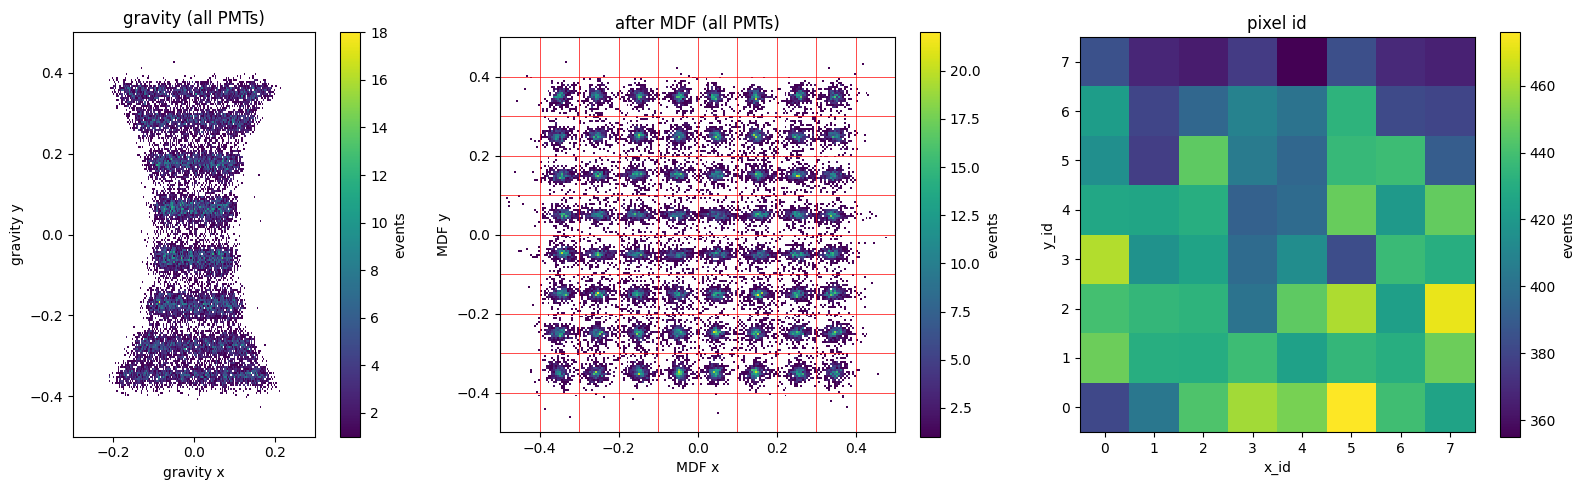

In [5]:
grv, mdf, pix = ev["HA_Gravity"], ev["HA_MDF"], ev["HA_Pixel"]
fig, ax = plt.subplots(1, 3, figsize=(17, 5))
h0 = ax[0].hist2d(grv[:, 0], grv[:, 1], bins=200, range=[[-0.3, 0.3], [-0.5, 0.5]], cmin=1)
ax[0].set_title("gravity (all PMTs)"); ax[0].set_xlabel("gravity x"); ax[0].set_ylabel("gravity y")
fig.colorbar(h0[3], ax=ax[0], label="events")
h1 = ax[1].hist2d(mdf[:, 0], mdf[:, 1], bins=200, range=[[-0.5, 0.5], [-0.5, 0.5]], cmin=1)
fig.colorbar(h1[3], ax=ax[1], label="events")
for b in np.arange(-0.4, 0.41, 0.1):
    ax[1].axvline(b, color="r", lw=0.5); ax[1].axhline(b, color="r", lw=0.5)
ax[1].set_title("after MDF (all PMTs)"); ax[1].set_xlabel("MDF x"); ax[1].set_ylabel("MDF y")
h2 = ax[2].hist2d(pix[:, 2], pix[:, 3], bins=8, range=[[-0.5, 7.5], [-0.5, 7.5]])
fig.colorbar(h2[3], ax=ax[2], label="events")
ax[2].set_title("pixel id"); ax[2].set_xlabel("x_id"); ax[2].set_ylabel("y_id")
for a in ax: a.set_aspect("equal")
fig.tight_layout(); plt.show()

## 5. エネルギースペクトル

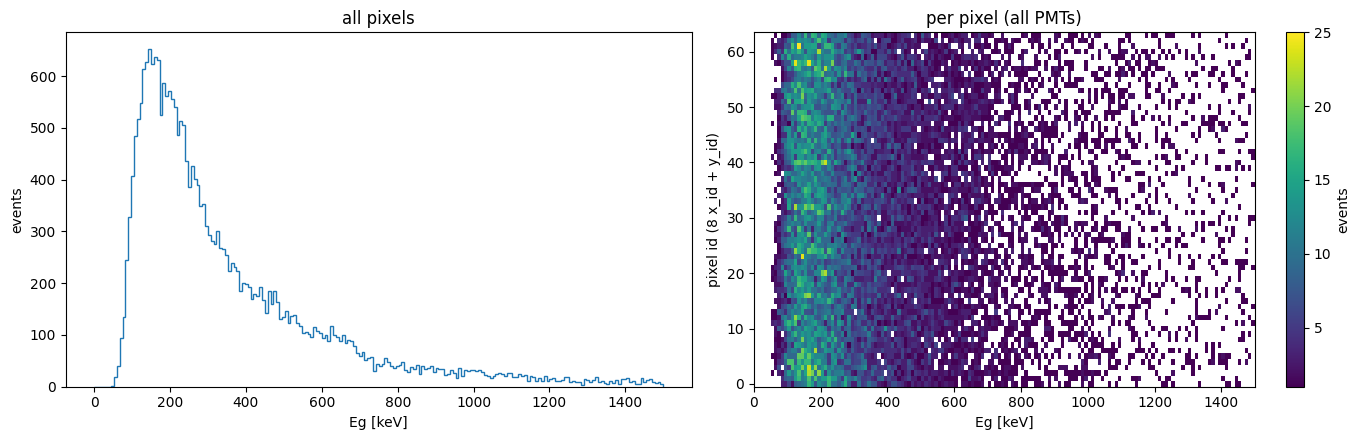

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].hist(ev["Eg"], bins=200, range=(0, 1500), histtype="step")
ax[0].set_xlabel("Eg [keV]"); ax[0].set_ylabel("events"); ax[0].set_title("all pixels")
pid = pix[:, 2] * 8 + pix[:, 3]
h = ax[1].hist2d(ev["Eg"], pid, bins=[150, 64], range=[[0, 1500], [-0.5, 63.5]], cmin=1)
fig.colorbar(h[3], ax=ax[1], label="events")
ax[1].set_xlabel("Eg [keV]"); ax[1].set_ylabel("pixel id (8 x_id + y_id)"); ax[1].set_title("per pixel (all PMTs)")
fig.tight_layout(); plt.show()